# 第 08 关：五因子的压力测试

**本关要回答的问题：** 加入 RMW 和 CMA 后，模型在哪些测试资产上减少了定价误差？还剩哪些误差解释不了？HML 在五因子中还有用吗？

### 为什么要换多组测试资产？
第 05 关用规模×B/M 组合检验三因子，相当于"主场"考试。FF2015 的检验更严格：它用六组测试资产，每组按不同的特征排序，模型要同时解释所有这些组合的平均收益。
- **三组 25 组合（5×5）**：规模 × B/M、规模 × OP、规模 × Inv。
- **三组 32 组合（2×4×4）**：规模分 2 档，另外两个特征各分 4 档，例如规模 × B/M × OP。它们检验模型能否同时处理两个特征之间的交互。

注意区分：**2×3 是构造因子用的分组，5×5、2×4×4 是测试资产的分组**，两者不必相同。

样本固定为 FF2015 的 1963-07 至 2013-12（606 个月），因子使用 2×3 构造的版本。原论文还比较了 2×2、2×2×2×2 等其他因子构造方式，本关只做 2×3 版本。各表在原文中的页码见下文链接和[论文表格导航](../papers/TABLE_GUIDE.md)。

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "course.py").exists()), None)
if ROOT is None:
    raise RuntimeError("请在 asset_pricing_quest 项目或其 notebooks 文件夹中启动 Notebook。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from course import load_returns, style, save_table, paper_note, build_ff5
from analysis import fit_models, model_summary

style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 24)

In [2]:
display(Markdown(paper_note("ff2015")))

**论文对照：** [Fama & French (2015), A five-factor asset pricing model](../papers/ff2015_primary_reference.pdf)。准确表号、PDF 页码和复现范围见 [论文表格导航](../papers/TABLE_GUIDE.md)。当前数据版本会与原文历史版本存在差异。

## 1. 三个模型
- **FF3 standard**：三因子文件中的 Mkt-RF、SMB、HML，即经典三因子模型。
- **FF3 common SMB**：五因子文件中的 Mkt-RF、SMB、HML。它与 FF5 共用完全相同的前三个因子。
- **FF5**：五因子文件的全部五列。

"FF3 common SMB"与"FF5"之间唯一的差别就是加入了 RMW、CMA，因此能干净地看出新因子的贡献，这也是 FF2015 Table 5 的做法。"FF3 standard"与"FF5"则是两个公开标准模型之间的比较，SMB 的定义也随之改变（见第 07 关）。所有模型使用相同的月份和测试组合。

In [3]:
START, END = "1963-07", "2013-12"
ff3 = load_returns("ff3", START, END)
ff5 = load_returns("ff5", START, END)
assert ff3.index.equals(ff5.index) and len(ff5) == 606
assert np.allclose(ff3["RF"], ff5["RF"])
names3 = ["Mkt-RF", "SMB", "HML"]
names5 = [*names3, "RMW", "CMA"]
models = {"FF3 standard": ff3[names3],
          "FF3 common SMB": ff5[names3],
          "FF5": ff5[names5]}
assets = {"Size × B/M (25)": "bm25", "Size × OP (25)": "op25", "Size × Inv (25)": "inv25",
          "Size × B/M × OP (32)": "bm_op32", "Size × B/M × Inv (32)": "bm_inv32",
          "Size × OP × Inv (32)": "op_inv32"}

## 2. 六组测试资产上的模型比较
对每组资产、每个模型，都跑一遍时间序列回归并汇总。指标与第 05 关相同：
- `mean_abs_alpha_pct_month`、`rms_alpha_pct_month`：平均绝对 α 与 α 均方根（%/月），衡量定价误差的大小；
- `mean_r2`：平均 R²，衡量对共同波动的解释程度；
- `grs_stat`、`grs_pvalue`：GRS 联合检验的统计量和 p 值。

读表提示：不同资产组的组合数和残差相关结构不同，GRS 的检验力也不同，所以跨资产组比较时，α 的大小比 p 值更可靠；在同一组资产内比较模型，可以同时看两者。

In [4]:
results, excess_by_set = [], {}
for label, key in assets.items():
    returns = load_returns(key, START, END)
    assert returns.index.equals(ff5.index)
    excess = returns.sub(ff5["RF"], axis=0)
    assert not excess.isna().any().any()
    excess_by_set[label] = excess
    comparison = model_summary(excess, models)
    comparison["asset_set"] = label
    results.append(comparison.reset_index(names="model"))
summary = pd.concat(results, ignore_index=True).set_index(["asset_set", "model"])
columns = ["mean_abs_alpha_pct_month", "rms_alpha_pct_month", "mean_r2", "grs_stat", "grs_pvalue"]
display(summary.loc[list(assets)[:3], columns].style.format(
    precision=4, formatter={"grs_pvalue": "{:.3g}"}))
display(summary.loc[list(assets)[3:], columns].style.format(
    precision=4, formatter={"grs_pvalue": "{:.3g}"}))
save_table(summary, "08_models_all_test_assets")

WindowsPath('E:/Eth data/asset_pricing_quest/results/08_models_all_test_assets.csv')

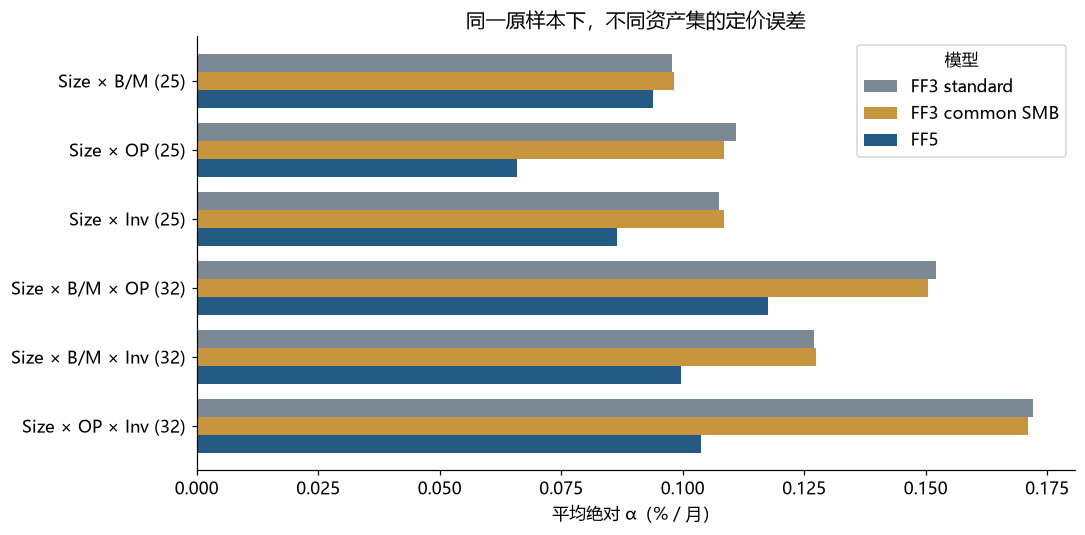

In [5]:
error_chart = summary["mean_abs_alpha_pct_month"].unstack("model")
error_chart = error_chart.loc[list(assets), list(models)]
fig, ax = plt.subplots(figsize=(10, 5))
error_chart.plot.barh(ax=ax, color=["#7b8994", "#c7953d", "#245b84"], width=0.78)
ax.set_xlabel("平均绝对 α（% / 月）")
ax.set_ylabel("")
ax.set_title("同一原样本下，不同资产集的定价误差")
ax.set_xlim(left=0)
ax.legend(title="模型", loc="best")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

In [6]:
delta = error_chart["FF3 common SMB"] - error_chart["FF5"]    # 正数 = 加入 RMW、CMA 后误差变小
improvement_count = int((delta > 0).sum())
ff5_pvalues = summary.xs("FF5", level="model")["grs_pvalue"]
display(Markdown(
    f"保持前三个因子相同时，FF5 在 **{improvement_count}/{len(delta)}** 组测试资产上的平均绝对 α 更小。"
    f"改善最多的是 **{delta.idxmax()}**（减少 {delta.max():.3f} 个百分点/月），"
    f"最少的是 **{delta.idxmin()}**（减少 {delta.min():.3f}）。"
    "按盈利、投资排序的资产改善明显，这在意料之中，因为 RMW、CMA 正是针对这两个特征设计的。\n\n"
    f"不过，FF5 的 GRS p 值在 {int((ff5_pvalues < .05).sum())}/{len(ff5_pvalues)} 组资产上低于 0.05："
    "五因子缩小了定价误差，但并没有消除它。"))

保持前三个因子相同时，FF5 在 **6/6** 组测试资产上的平均绝对 α 更小。改善最多的是 **Size × OP × Inv (32)**（减少 0.067 个百分点/月），最少的是 **Size × B/M (25)**（减少 0.004）。按盈利、投资排序的资产改善明显，这在意料之中，因为 RMW、CMA 正是针对这两个特征设计的。

不过，FF5 的 GRS p 值在 6/6 组资产上低于 0.05：五因子缩小了定价误差，但并没有消除它。

## 3. 从汇总指标回到具体组合
汇总指标可能掩盖少数大误差。下面以规模×盈利 25 组合为例，列出五因子下绝对 α 最大的五个组合，看误差集中在哪里。组合名中 ME 是规模档、OP 是盈利档（例如 `ME4 OP1` 是规模第 4 档、盈利最低档）。这里的 t 值是逐个组合的检验，用来定位问题，不替代 GRS 联合检验。

In [7]:
portfolio_results, residuals = fit_models(excess_by_set["Size × OP (25)"], models["FF5"])
worst_names = portfolio_results["alpha"].abs().nlargest(5).index
display(portfolio_results.loc[worst_names, ["alpha_pct_month", "t_alpha_ols", "t_alpha_hac", "r2"]].round(4))
save_table(portfolio_results, "08_ff5_size_op_individual_regressions")

,alpha_pct_month,t_alpha_ols,t_alpha_hac,r2
asset,,,,
ME4 OP1,0.1794,2.2293,2.2522,0.9057
SMALL HiOP,-0.1350,-1.8648,-1.7758,0.9375
ME4 OP4,-0.1276,-2.0468,-2.0004,0.9149
ME5 OP2,-0.1007,-1.7845,-1.6976,0.9175
ME2 OP4,-0.0997,-1.7217,-1.5254,0.9425


WindowsPath('E:/Eth data/asset_pricing_quest/results/08_ff5_size_op_individual_regressions.csv')

## 4. HML 在五因子中还有增量作用吗？
FF2015 最引人注目的发现之一：加入 RMW 和 CMA 之后，HML 变得**冗余**。检验方法叫**涵盖回归**（spanning regression）：把 HML 的收益对其余四个因子回归，

$$
HML_t=a+b\,MKT_t+s\,SMB_t+r\,RMW_t+c\,CMA_t+e_t.
$$

逻辑是这样的：HML 本身是一个可投资的组合。如果它的平均收益能被其他四个因子的某个组合完全复制（截距 $a=0$），那么投资者只用其他四个因子就能得到 HML 能提供的全部平均收益，模型中有没有 HML，对解释平均收益没有区别。如果 $a$ 显著不为零，HML 就提供了其他因子没有的信息。

第一张表是涵盖回归的结果；第二张表从另一个角度验证：在规模×B/M 25 组合上，比较去掉 HML 的四因子模型与五因子模型。

In [8]:
other4 = ff5[["Mkt-RF", "SMB", "RMW", "CMA"]]
hml_result, hml_residual = fit_models(ff5[["HML"]], other4)
display(hml_result[["alpha_pct_month", "t_alpha_ols", "t_alpha_hac", "r2"]].round(4))
four_five = model_summary(excess_by_set["Size × B/M (25)"], {"FF4 without HML": other4, "FF5": models["FF5"]})
display(four_five[columns].style.format(precision=4, formatter={"grs_pvalue": "{:.3g}"}))
save_table(hml_result, "08_hml_incremental_regression")
save_table(four_five, "08_four_vs_five_size_bm")

,alpha_pct_month,t_alpha_ols,t_alpha_hac,r2
asset,,,,
HML,-0.0079,-0.093,-0.0735,0.5011


,mean_abs_alpha_pct_month,rms_alpha_pct_month,mean_r2,grs_stat,grs_pvalue
model,,,,,
FF4 without HML,0.0952,0.1218,0.8930,3.0902,9.89e-07
FF5,0.0939,0.1210,0.9194,3.1199,7.84e-07


WindowsPath('E:/Eth data/asset_pricing_quest/results/08_four_vs_five_size_bm.csv')

In [9]:
h = hml_result.loc["HML"]
display(Markdown(
    f"HML 涵盖回归的截距为 **{h['alpha_pct_month']:.4f}%/月**（HAC t = {h['t_alpha_hac']:.3f}），R² = {h['r2']:.2f}。"
    "截距几乎为零：HML 的平均收益可以完全由它对其他四个因子的暴露解释。"
    f"其中它对 CMA 的斜率为 {h['beta_CMA']:.2f}，说明价值股往往也是投资少的公司，HML 的平均收益主要通过 CMA 得到解释。\n\n"
    "第二张表印证了这一点：在规模×B/M 组合上，去掉 HML 的四因子模型与五因子模型的平均绝对 α 几乎相同。"
    "这与 FF2015 的结论一致：在这段样本中，HML 对解释平均收益是冗余的。"))

HML 涵盖回归的截距为 **-0.0079%/月**（HAC t = -0.073），R² = 0.50。截距几乎为零：HML 的平均收益可以完全由它对其他四个因子的暴露解释。其中它对 CMA 的斜率为 1.01，说明价值股往往也是投资少的公司，HML 的平均收益主要通过 CMA 得到解释。

第二张表印证了这一点：在规模×B/M 组合上，去掉 HML 的四因子模型与五因子模型的平均绝对 α 几乎相同。这与 FF2015 的结论一致：在这段样本中，HML 对解释平均收益是冗余的。

## 5. 对照原文详细系数表：HMLO
FF2015 的详细回归表（例如 [Table 7，第 13 页](../papers/ff2015_primary_reference.pdf#page=13)，以及 Table 9、10、11、A2、A3）没有直接使用 HML，而是使用 **HMLO**（orthogonalized HML，正交化的 HML）：

$$
HMLO_t=a+e_t=HML_t-(b\,MKT_t+s\,SMB_t+r\,RMW_t+c\,CMA_t),
$$

即上面涵盖回归的截距加残差。它把 HML 中能被其他四个因子线性复制的部分剥掉，只留下"HML 独有的部分"；因为保留了截距，HMLO 的平均收益不变。

用 HMLO 替换 HML 只是同一个模型的另一种写法：五个因子能组合出的收益空间没有变，所以每个组合的 α、残差、R² 都完全不变，HMLO 的斜率也等于原来 HML 的斜率；变的只是其他四个因子的斜率，它们吸收了原本通过 HML 体现的那部分暴露。

下面先用数值验证这几点（所有差异都小于 1e-10），再展示规模×B/M 25 组合的详细系数。系数是无单位的暴露，α 的单位是 %/月；t 值为普通 OLS t 值，与原文的口径一致。

In [10]:
hmlo = hml_result.loc["HML", "alpha"] + hml_residual["HML"]
orthogonal_factors = ff5[["Mkt-RF", "SMB", "RMW", "CMA"]].copy()
orthogonal_factors.insert(2, "HMLO", hmlo)
bm_excess = excess_by_set["Size × B/M (25)"]
original_details, original_residuals = fit_models(bm_excess, models["FF5"])
hmlo_details, hmlo_errors = fit_models(bm_excess, orthogonal_factors)
equivalence = pd.Series({
    "max_alpha_difference": (hmlo_details["alpha"]-original_details["alpha"]).abs().max(),
    "max_r2_difference": (hmlo_details["r2"]-original_details["r2"]).abs().max(),
    "max_residual_difference": (hmlo_errors-original_residuals).abs().to_numpy(dtype=float).max(),
    "max_HML_loading_difference": (hmlo_details["beta_HMLO"]-original_details["beta_HML"]).abs().max(),
}, name="重参数化核验")
assert (equivalence < 1e-10).all()
display(equivalence.to_frame().style.format("{:.3g}"))
x_hmlo = sm.add_constant(orthogonal_factors)
for asset in bm_excess:
    detailed_fit = sm.OLS(bm_excess[asset], x_hmlo).fit()
    for name in orthogonal_factors:
        hmlo_details.loc[asset, "t_ols_" + name] = detailed_fit.tvalues[name]
detail_columns = ["alpha_pct_month", "t_alpha_ols", "beta_Mkt-RF", "beta_SMB", "beta_HMLO", "beta_RMW", "beta_CMA"]
display(hmlo_details[detail_columns].style.format(precision=4))
save_table(hmlo_details, "08_table7_hmlo_detailed_coefficients")
save_table(equivalence.to_frame(), "08_hmlo_equivalence_checks")

,重参数化核验
max_alpha_difference,5.2e-17
max_r2_difference,1.11e-16
max_residual_difference,6.52e-16
max_HML_loading_difference,1.33e-15


,alpha_pct_month,t_alpha_ols,beta_Mkt-RF,beta_SMB,beta_HMLO,beta_RMW,beta_CMA
asset,,,,,,,
SMALL LoBM,-0.2747,-3.0569,1.0454,1.2307,-0.3898,-0.5386,-0.5613
ME1 BM2,0.1574,2.2457,0.9248,1.2287,-0.1211,-0.4227,-0.1839
ME1 BM3,-0.0224,-0.3987,0.9414,1.0766,0.1385,-0.0154,0.1805
ME1 BM4,0.1772,3.2041,0.8929,1.0715,0.2607,-0.0104,0.3325
SMALL HiBM,0.1057,1.7478,0.9805,1.0859,0.4935,0.0932,0.5949
ME2 BM1,-0.0694,-1.1029,1.0857,0.9575,-0.4705,-0.2409,-0.6037
ME2 BM2,-0.0545,-0.9981,1.0221,0.9486,-0.0317,0.0842,0.0205
ME2 BM3,-0.0159,-0.2840,0.9852,0.8209,0.2855,0.2870,0.2801
ME2 BM4,0.0116,0.2288,0.9770,0.7466,0.3969,0.1892,0.5103


WindowsPath('E:/Eth data/asset_pricing_quest/results/08_hmlo_equivalence_checks.csv')

## 6. 原文数字对照
[Table 5，第 9 页](../papers/ff2015_primary_reference.pdf#page=9)报告各模型在各组资产上的 GRS 和平均绝对 α。这里对照其中两个面板，三因子一栏取"FF3 common SMB"，与原文口径一致。[Table 6，第 11 页](../papers/ff2015_primary_reference.pdf#page=11)报告 HML 的涵盖回归，原文 t 值是普通 OLS t 值，所以这里也用 OLS t 值对照。

原文数值来自 `papers/paper_map.json`。`current_minus_paper` 是重算值减原文值，`unit` 是单位。差异主要来自 French 对历史数据的修订，包括 OP 定义的更新。

In [11]:
import json
paper_map = json.loads((ROOT / "papers" / "paper_map.json").read_text(encoding="utf-8"))
asset_lookup = {"25 Size-B/M": "Size × B/M (25)", "32 Size-OP-Inv": "Size × OP × Inv (32)"}
model_lookup = {"FF3_FF5_SMB": "FF3 common SMB", "FF5": "FF5"}
metric_lookup = {"GRS": "grs_stat", "mean_absolute_alpha": "mean_abs_alpha_pct_month"}
spanning_lookup = {"spanning_alpha": "alpha_pct_month", "spanning_alpha_t": "t_alpha_ols", "r_squared": "r2"}
anchor_rows = []
for anchor in paper_map["numeric_anchors"]:
    if anchor["paper"] != "ff2015" or anchor["table"] not in ("5", "6"):
        continue
    if anchor["table"] == "5":
        current = summary.loc[(asset_lookup[anchor["key"]], model_lookup[anchor["model"]]), metric_lookup[anchor["metric"]]]
        item = f"Table 5{anchor['panel']} / {anchor['model']} / {anchor['metric']}"
    else:
        current = hml_result.loc["HML", spanning_lookup[anchor["metric"]]]
        item = "Table 6 / HML / " + anchor["metric"]
    anchor_rows.append({"item": item, "paper_value": anchor["paper_value"],
                        "current_value": current, "current_minus_paper": current-anchor["paper_value"],
                        "unit": anchor["unit"]})
paper_comparison = pd.DataFrame(anchor_rows).set_index("item")
display(paper_comparison.style.format(precision=4))
save_table(paper_comparison, "08_table5_table6_paper_comparison")

,paper_value,current_value,current_minus_paper,unit
item,,,,
Table 5A / FF3_FF5_SMB / GRS,3.6200,3.5725,-0.0475,dimensionless
Table 5A / FF3_FF5_SMB / mean_absolute_alpha,0.1020,0.0981,-0.0039,percent_per_month
Table 5A / FF5 / GRS,2.8400,3.1199,0.2799,dimensionless
Table 5A / FF5 / mean_absolute_alpha,0.0940,0.0939,-0.0001,percent_per_month
Table 5F / FF3_FF5_SMB / GRS,4.3800,4.1206,-0.2594,dimensionless
Table 5F / FF3_FF5_SMB / mean_absolute_alpha,0.1820,0.1711,-0.0109,percent_per_month
Table 5F / FF5 / GRS,2.9200,2.8536,-0.0664,dimensionless
Table 5F / FF5 / mean_absolute_alpha,0.1030,0.1038,0.0008,percent_per_month
Table 6 / HML / spanning_alpha,-0.0400,-0.0079,0.0321,percent_per_month


WindowsPath('E:/Eth data/asset_pricing_quest/results/08_table5_table6_paper_comparison.csv')

## 7. 结论能推到哪里
- **五因子在每组测试资产上都缩小了定价误差**，改善集中在按盈利、投资排序的组合上；在规模×B/M 组合上几乎没有改善。
- **五因子仍然被 GRS 拒绝**：六组资产上仍有系统性的定价误差。FF2015 指出，最难解释的是一类小盘股：它们的收益表现像"盈利低、投资却很多"的公司，平均收益低到模型无法解释。
- **HML 冗余是这段样本的结论**：它依赖 HML 与 CMA 的高度相关。换一段时期是否仍然成立，是第 09 关可以检验的问题。

## 通关证据与 Boss 作答区

提交：六组测试资产的比较表、对一个误差较大组合的分析、HML 涵盖回归与"去掉 HML"的比较。

**Boss：** HML 涵盖回归的截距不显著。你会怎样表述这个结论？哪些更强的说法（例如"价值效应不存在""价值因子可以永久删除"）需要额外的证据？

**你的回答：**

（留空，运行与思考后填写。）